# ***Qualify: sleep quality prediction***
This notebook presents the development and evaluation of ML models for predicting sleep quality. It combines data preprocessing, exploratory data analysis, feature engineering, model training, hyperparameter tuning, and performance evaluation for both regression and classification tasks.

# Notebook Overview
 1. Data Loading and Cleaning

 2. Exploratory Data Analysis (EDA)

 3. Data Splitting and Preprocessing

 4. Feature Analysis and Engineering

 5. Regression and Classification Models

 6. Random Forest Regression and Classification Models

 7. Final Model Comparison and Selection

## 1. Data Loading and Cleaning
1.1 Setup and Data Loading
- Library Imports
- Loading Dataset

1.2 Data Cleaning
- Standardizing column names
- Removing Duplicates
- Handling Missing and Invalid Values
- Creating Sleep Quality Classes
- Sleep Quality Class Distribution (might delete)

### 1.1 Setup and Data Loading

#### Library Imports

In [65]:
# General libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Data splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Regression models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Evaluation metrics
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

#### Loading Dataset

In [66]:
# Project paths
RAW = "../data/raw"
OUT = "../data/processed"
FIG = "../figures"
RES = "../results"

for folder in [OUT, FIG, RES]:
    os.makedirs(folder, exist_ok=True)


RANDOM_STATE = 42

TARGET = "quality_of_sleep"
CLASS = "sleep_quality_class"
CLASS_ORDER = ["low", "medium", "high"]


NUM_FEATURES = [
    "age", "daily_steps", "heart_rate",
    "physical_activity_level", "sleep_duration", "stress_level"
]

CAT_FEATURES = ["gender", "bmi_category"]

FEATURES = [
    "age", "gender", "bmi_category", "daily_steps",
    "heart_rate", "physical_activity_level",
    "sleep_duration", "stress_level"
]

In [67]:
df = pd.read_csv(
    f"{RAW}/Sleep_health_and_lifestyle_dataset.csv",
    keep_default_na=False,
    na_values=[""]
)

print("Original shape:", df.shape)

Original shape: (374, 13)


### 1.2 Data Cleaning

#### Standardizing column names

In [ ]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^\w]+", "_", regex=True)
    .str.strip("_")
)

# Standardize categorical text
for col in df.select_dtypes(include=["object", "str"]).columns:
    df[col] = df[col].str.strip().str.lower()

# Make BMI categories consistent
df["bmi_category"] = df["bmi_category"].replace({
    "normal weight": "normal"
})

print("Columns:", df.columns.tolist())

Columns: ['person_id', 'gender', 'age', 'occupation', 'sleep_duration', 'quality_of_sleep', 'physical_activity_level', 'stress_level', 'bmi_category', 'blood_pressure', 'heart_rate', 'daily_steps', 'sleep_disorder']


#### Removing Duplicates

In [69]:
df = df.drop(columns=["person_id"])
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print(df.head())

Shape after removing duplicates: (132, 12)
  gender  age            occupation  sleep_duration  quality_of_sleep  \
0   male   27     software engineer             6.1                 6   
1   male   28                doctor             6.2                 6   
2   male   28  sales representative             5.9                 4   
3   male   28     software engineer             5.9                 4   
4   male   29               teacher             6.3                 6   

   physical_activity_level  stress_level bmi_category blood_pressure  \
0                       42             6   overweight         126/83   
1                       60             8       normal         125/80   
2                       30             8        obese         140/90   
3                       30             8        obese         140/90   
4                       40             7        obese         140/90   

   heart_rate  daily_steps sleep_disorder  
0          77         4200           none

#### Handling Missing and Invalid Values

In [70]:
print("Missing values:\n", df.isna().sum())

df = df.dropna(subset=[TARGET]).copy()

invalid = (
    (df["age"] < 18) |
    (df["heart_rate"] > 120) |
    (df["sleep_duration"] > 12)
)

print("Invalid rows:", invalid.sum())

df = df.loc[~invalid].reset_index(drop=True)

print("Final shape:", df.shape)

Missing values:
 gender                     0
age                        0
occupation                 0
sleep_duration             0
quality_of_sleep           0
physical_activity_level    0
stress_level               0
bmi_category               0
blood_pressure             0
heart_rate                 0
daily_steps                0
sleep_disorder             0
dtype: int64
Invalid rows: 0
Final shape: (132, 12)


#### Creating Sleep Quality Classes

In [71]:
df[CLASS] = pd.cut(
    df[TARGET],
    bins=[-np.inf, 6, 8, np.inf],
    labels=CLASS_ORDER,
    right=False
).astype(str)

print(df[TARGET].describe())
print("\nClass counts:")
print(df[CLASS].value_counts().reindex(CLASS_ORDER))

count    132.000000
mean       7.151515
std        1.269037
min        4.000000
25%        6.000000
50%        7.000000
75%        8.000000
max        9.000000
Name: quality_of_sleep, dtype: float64

Class counts:
sleep_quality_class
low       10
medium    65
high      57
Name: count, dtype: int64


#### Sleep Quality Class Distribution

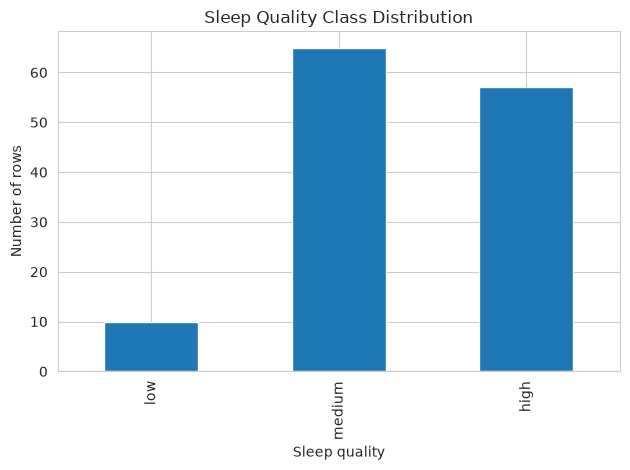

In [72]:
df[CLASS].value_counts().reindex(CLASS_ORDER).plot(kind="bar")

plt.title("Sleep Quality Class Distribution")
plt.xlabel("Sleep quality")
plt.ylabel("Number of rows")
plt.tight_layout()
plt.savefig(f"{FIG}/label_distribution.png", dpi=150)
plt.show()

## 2. Exploratory Data Analysis (EDA)

2.1 Visualization Setup and Dataset Overview (fix this --> short title for each cell)
- Configure Visualization Settings
- Display dataset shape, column name, dtype 

2.2 Summary Statistics (fix this --> short title for each cell)
- Summarize numeric features e.g. sleep duration, stress levels, physical activity such as daily steps taken
- Use the results to interpret and draw conclusions about the range and identify possible anomaly or unusal outliers

2.3 Sleep Quality Classes
- Count how many records are classified as low,medium, and high quality
- A bar chart will be used to visualize frequency in each category

2.4 Visualizing Feature Distributions

2.5 Correlation Heatmap

2.6 Assessing Sleep Quality against other features

### 2.1 Visualization Setup and Dataset Overview 

#### Visualization Settings

In [73]:
sns.set_style("whitegrid")

labels = {
    "age": "Age (years)",
    "daily_steps": "Daily steps",
    "heart_rate": "Resting heart rate (bpm)",
    "physical_activity_level": "Physical activity (min/day)",
    "sleep_duration": "Sleep duration (hours)",
    "stress_level": "Stress level (1-10)",
    "quality_of_sleep": "Sleep quality (1-10)",
    "gender_male": "Gender (male = 1)",
    "bmi_order": "BMI category (ordered)"
}

class_order = CLASS_ORDER
class_colors = ["#d9534f", "#f0ad4e", "#5cb85c"]
num_cols = NUM_FEATURES

#### Dataset Overview

In [74]:
print("Shape:", df.shape)
df.head()

Shape: (132, 13)


,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder,sleep_quality_class
0,male,27,software engineer,6.1,6,42,6,overweight,126/83,77,4200,none,medium
1,male,28,doctor,6.2,6,60,8,normal,125/80,75,10000,none,medium
2,male,28,sales representative,5.9,4,30,8,obese,140/90,85,3000,sleep apnea,low
3,male,28,software engineer,5.9,4,30,8,obese,140/90,85,3000,insomnia,low
4,male,29,teacher,6.3,6,40,7,obese,140/90,82,3500,insomnia,medium


In [75]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   gender                   132 non-null    str    
 1   age                      132 non-null    int64  
 2   occupation               132 non-null    str    
 3   sleep_duration           132 non-null    float64
 4   quality_of_sleep         132 non-null    int64  
 5   physical_activity_level  132 non-null    int64  
 6   stress_level             132 non-null    int64  
 7   bmi_category             132 non-null    str    
 8   blood_pressure           132 non-null    str    
 9   heart_rate               132 non-null    int64  
 10  daily_steps              132 non-null    int64  
 11  sleep_disorder           132 non-null    str    
 12  sleep_quality_class      132 non-null    str    
dtypes: float64(1), int64(6), str(6)
memory usage: 13.5 KB


In [76]:
print("Missing values per column:")
print(df.isna().sum())

Missing values per column:
gender                     0
age                        0
occupation                 0
sleep_duration             0
quality_of_sleep           0
physical_activity_level    0
stress_level               0
bmi_category               0
blood_pressure             0
heart_rate                 0
daily_steps                0
sleep_disorder             0
sleep_quality_class        0
dtype: int64


Based on the output results, the clean and processed dataset contains 2091 rows. Only stress_level feature has missing values, namely 63 rows, which contributes to approximately 3%. The missing rows in both the raw versions of the dataset were filled with the training median when building the model.

### 2.2 Summary Statistics

In [77]:
df[num_cols +[TARGET]].describe().round(2)

,age,daily_steps,heart_rate,physical_activity_level,sleep_duration,stress_level,quality_of_sleep
count,132.00,132.00,132.00,132.00,132.00,132.00,132.00
mean,41.13,6637.88,71.20,58.39,7.08,5.54,7.15
std,8.81,1766.29,4.87,20.47,0.78,1.74,1.27
min,27.00,3000.00,65.00,30.00,5.80,3.00,4.00
25%,33.75,5000.00,68.00,44.25,6.40,4.00,6.00
50%,41.00,7000.00,70.00,60.00,7.15,6.00,7.00
75%,49.00,8000.00,74.00,75.00,7.72,7.00,8.00
max,59.00,10000.00,86.00,90.00,8.50,8.00,9.00


In [78]:
# Count outliers with the IQR rule (more than 1.5 * IQR outside the quartiles)
for col in num_cols + [TARGET]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(col, ":", len(outliers), "outliers")

age : 0 outliers
daily_steps : 0 outliers
heart_rate : 5 outliers
physical_activity_level : 0 outliers
sleep_duration : 0 outliers
stress_level : 0 outliers
quality_of_sleep : 0 outliers


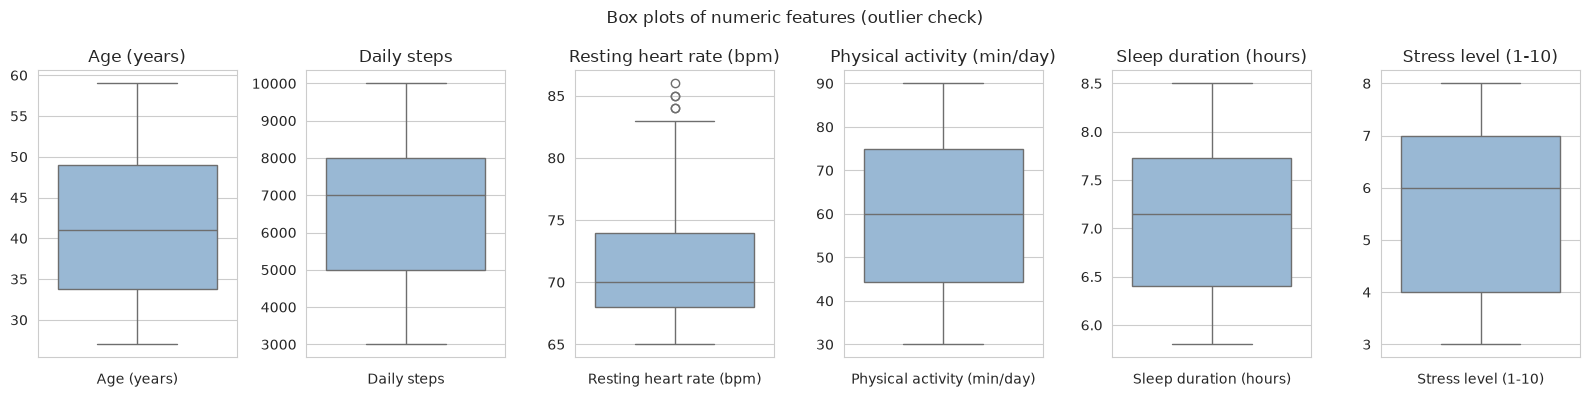

In [79]:
fig, axes = plt.subplots(1, 6, figsize=(16, 4))
for i in range(6):
    col = num_cols[i]
    sns.boxplot(y=df[col], ax=axes[i], color="#8fb8de")
    axes[i].set_title(labels[col])
    axes[i].set_xlabel(labels[col])
    axes[i].set_ylabel("")
plt.suptitle("Box plots of numeric features (outlier check)")
plt.tight_layout()
plt.savefig(FIG + "/eda_01_boxplots_outliers.png")
plt.show()

### 2.3 Sleep Quality Classes

In [80]:
counts = df[CLASS].value_counts()[class_order]
percent = (counts / len(df) * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": percent}))

                     count  percent
sleep_quality_class                
low                     10      7.6
medium                  65     49.2
high                    57     43.2


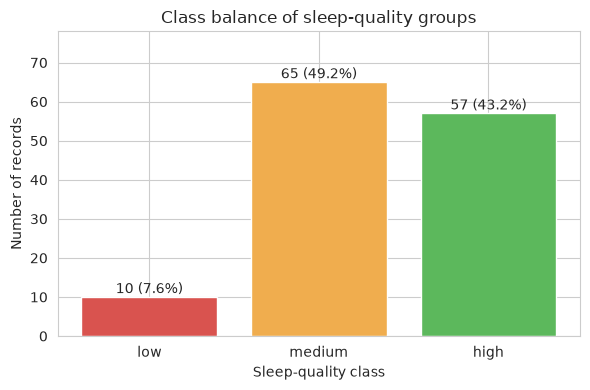

In [81]:
plt.figure(figsize=(6, 4))
plt.bar(class_order, counts, color=class_colors)
for i in range(3):
    plt.text(i, counts.iloc[i] + 1, str(counts.iloc[i]) + " (" + str(percent.iloc[i]) + "%)", ha="center")
plt.title("Class balance of sleep-quality groups")
plt.xlabel("Sleep-quality class")
plt.ylabel("Number of records")
plt.ylim(0, max(counts) * 1.2)
plt.tight_layout()
plt.savefig(FIG + "/eda_02_class_balance.png")
plt.show()

### 2.4 Visualizing Feature Distributions

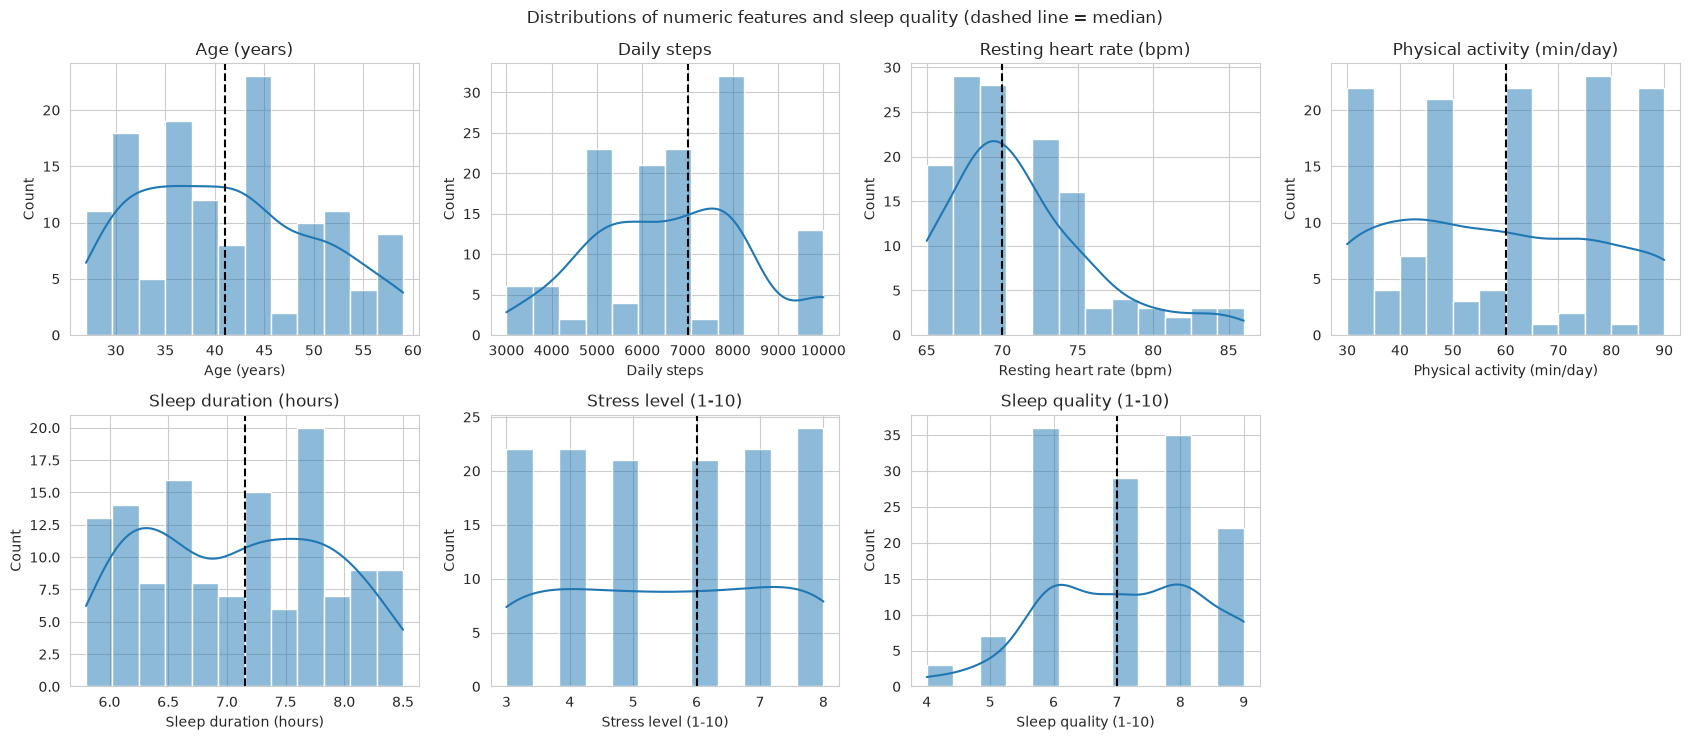

In [82]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
axes = axes.flatten()
for i in range(7):
    col = (num_cols + [TARGET])[i]
    sns.histplot(df[col], bins=12, kde=True, ax=axes[i])
    axes[i].axvline(df[col].median(), color="black", linestyle="--")
    axes[i].set_title(labels[col])
    axes[i].set_xlabel(labels[col])
    axes[i].set_ylabel("Count")
axes[7].axis("off")
plt.suptitle("Distributions of numeric features and sleep quality (dashed line = median)")
plt.tight_layout()
plt.savefig(FIG + "/eda_03_numeric_distributions.png")
plt.show()

Figure: The output demonstrates a set of histograms representing numeric features and sleep quality score. The dashed line intersecting the distribution indicates the median. The mean score of sleep quality is approximately 7.04

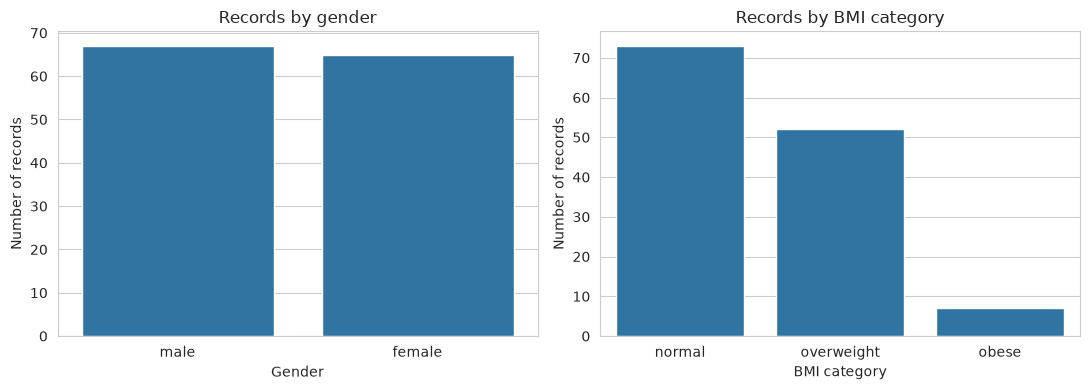

gender
male      67
female    65
Name: count, dtype: int64
bmi_category
normal        73
overweight    52
obese          7
Name: count, dtype: int64


In [83]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="gender", data=df, ax=axes[0])
axes[0].set_title("Records by gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of records")
sns.countplot(x="bmi_category", data=df, ax=axes[1], order=["normal", "overweight", "obese"])
axes[1].set_title("Records by BMI category")
axes[1].set_xlabel("BMI category")
axes[1].set_ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIG + "/eda_04_categorical_counts.png")
plt.show()
print(df["gender"].value_counts())
print(df["bmi_category"].value_counts())

Figure caption: Number of genders and by BMI category. Gender prominent in the dataset is balanced while majority of records fall roughly within the normal BMI with only 6 being obese.

### 2.5 Corralation Heatmap

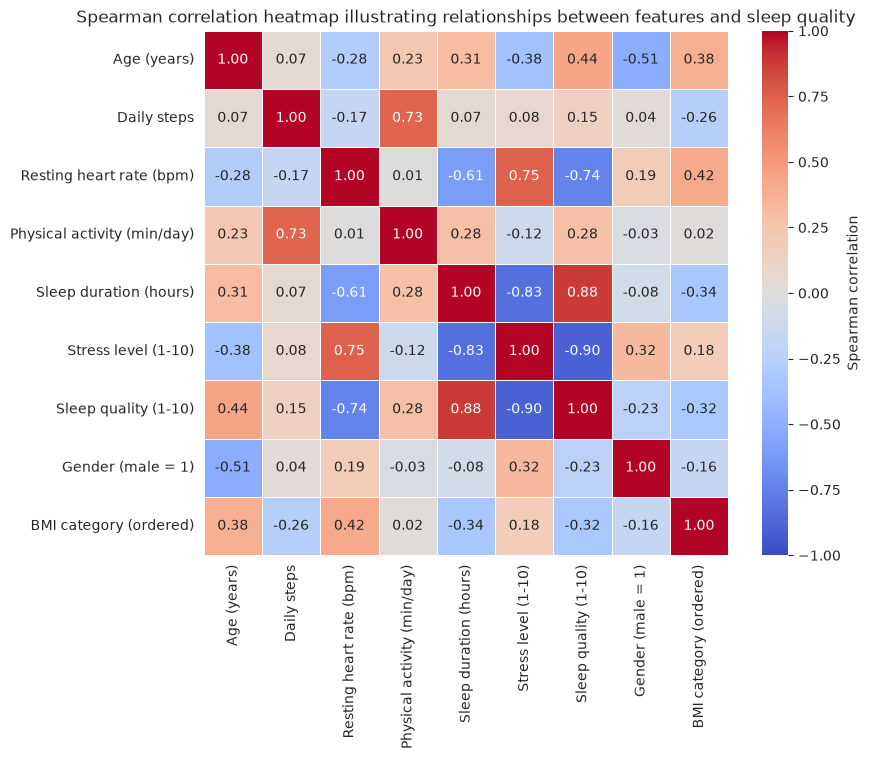

In [84]:
corr_data= df[num_cols + [TARGET]].copy()
corr_data["gender_male"]= (df["gender"]=="male").astype(int)
corr_data["bmi_order"]=df["bmi_category"].map({"underweight":0,"normal": 1,"overweight":2,"obese":3})

corr= corr_data.corr(method="spearman")
corr_display= corr.rename(index=labels, columns=labels)

plt.figure(figsize=(9,7.5))
sns.heatmap(corr_display, annot=True, fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1,cbar_kws={"label": "Spearman correlation"}, square=True, linewidths=0.5)
plt.title("Spearman correlation heatmap illustrating relationships between features and sleep quality")
plt.tight_layout()
plt.savefig(FIG + "/eda_05_correlation_heatmap.png")
plt.show()

In [85]:
print("Spearman correlation with sleep quality: ")
print(corr[TARGET].drop(TARGET).sort_values().round(2))

Spearman correlation with sleep quality: 
stress_level              -0.90
heart_rate                -0.74
bmi_order                 -0.32
gender_male               -0.23
daily_steps                0.15
physical_activity_level    0.28
age                        0.44
sleep_duration             0.88
Name: quality_of_sleep, dtype: float64


Spearman correlation between the features and the sleep-quality score (gender coded male = 1, BMI category ordered from underweight to obese). Stress level has the strongest link with sleep quality (negative), followed by heart rate (negative) and sleep duration (positive). Daily steps and physical activity are strongly related to each other (0.83).

### 2.6 Assessing Sleep Quality against every other feature

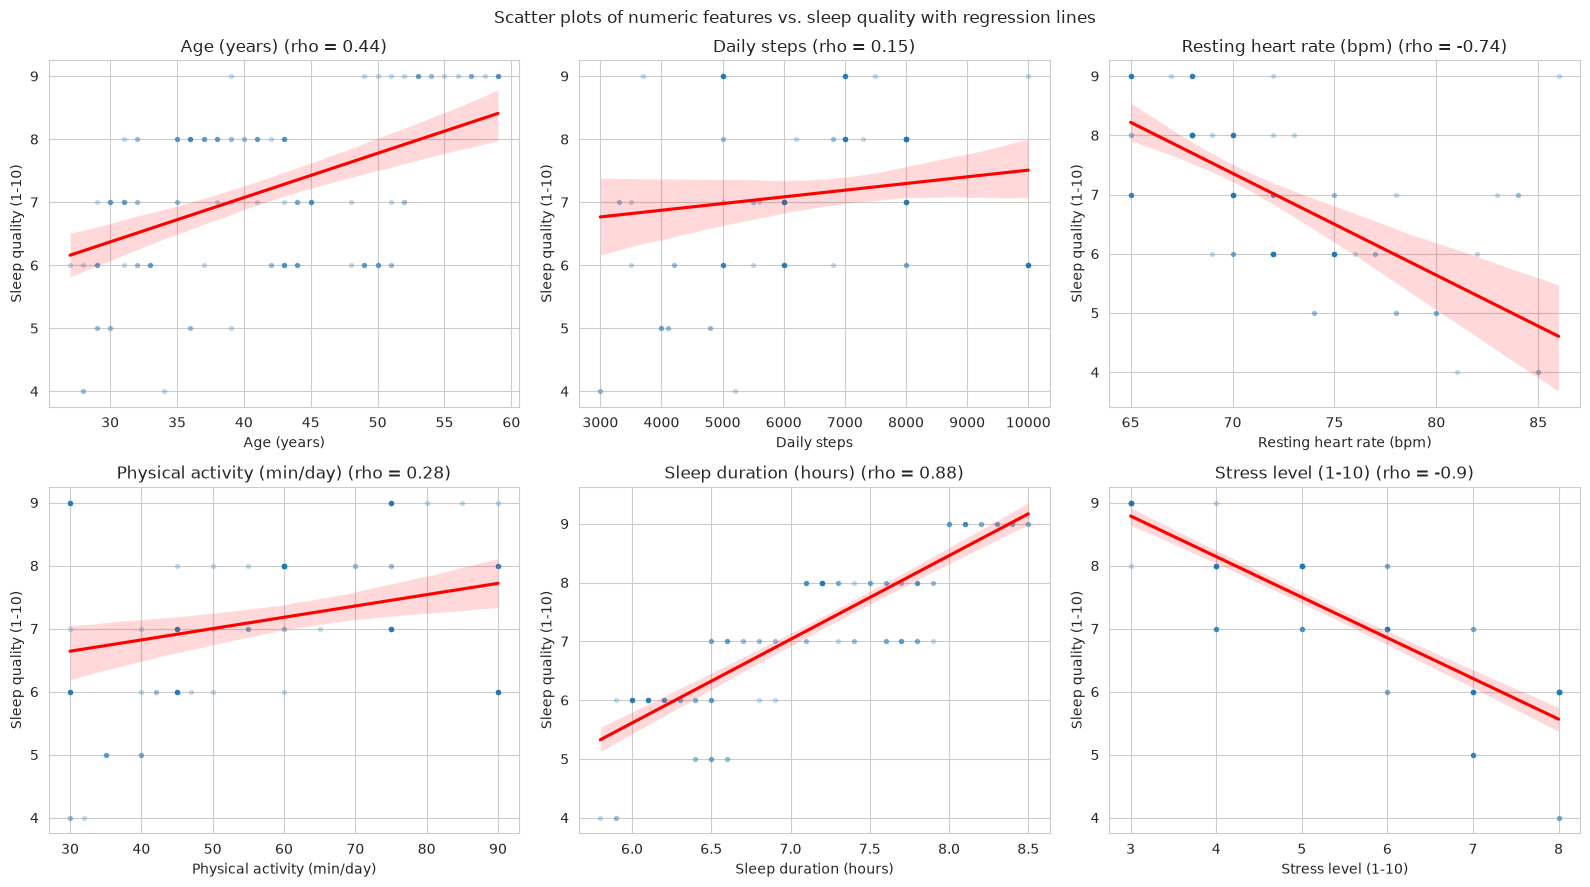

In [86]:
fig, axes = plt.subplots(2,3, figsize=(16,9))
axes=axes.flatten()
for i in range(6):
    col = num_cols[i] # Retrieves column name for the current iteration
    sns.regplot(x=col, y=TARGET, data=df, ax=axes[i], scatter_kws={"s":8,"alpha": 0.2}, line_kws={"color":"red"})
    # In seaborn, the parameter scatter_kws controls the size andtransparency of the scatter points while line_kws defines the color of the regression line
    r = round(df[col].corr(df[TARGET],method="spearman"),2)
    # r contains the Spearman correlation coefficient between the current column and the target variable, and the final value is rounded to two decimals places for better readability
    axes[i].set_title(labels[col] + " (rho = " + str(r) + ")")
    axes[i].set_xlabel(labels[col])
    axes[i].set_ylabel("Sleep quality (1-10)")
# suptitle() is used to set a title for the entire figure
plt.suptitle("Scatter plots of numeric features vs. sleep quality with regression lines")
plt.tight_layout()
plt.savefig(FIG + "/eda_06_scatterplots_regression.png")
plt.show()

Figure caption: Demonstrates sleep quality score against each numeric feature, with a fitted trend line visualized in red. Sleep quality evidently drops as stress levels and heart rate spike and similarly, is improved with more stable sleep. However, factors such as age, daily steps, and activity virtually show no correlation.

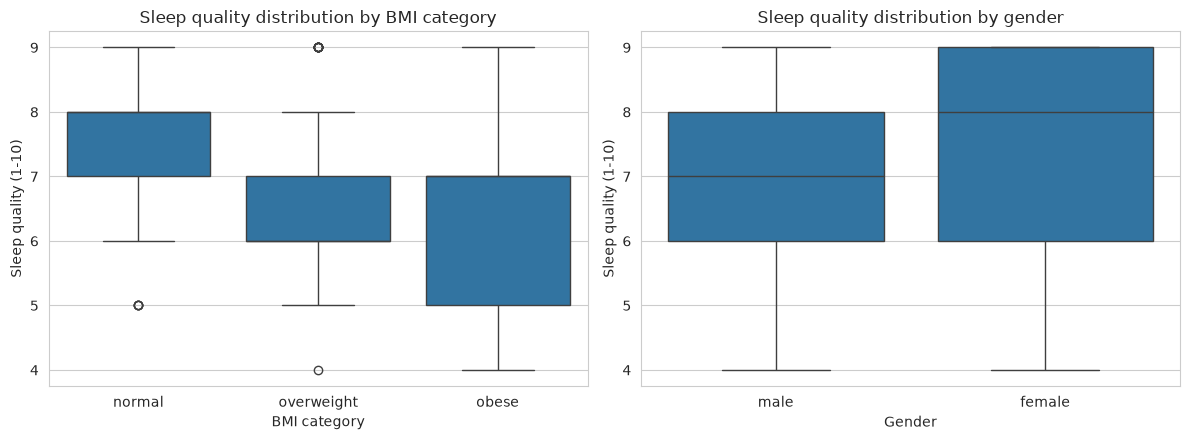

bmi_category
normal        7.51
obese         6.29
overweight    6.77
Name: quality_of_sleep, dtype: float64
gender
female    7.45
male      6.87
Name: quality_of_sleep, dtype: float64


In [87]:
fig, axes=plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x="bmi_category", y=TARGET, data=df, ax=axes[0], order=["normal", "overweight", "obese"])
axes[0].set_title("Sleep quality distribution by BMI category")
axes[0].set_xlabel("BMI category")
axes[0].set_ylabel("Sleep quality (1-10)")

sns.boxplot(x="gender", y=TARGET, data=df, ax=axes[1])
axes[1].set_title("Sleep quality distribution by gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Sleep quality (1-10)")

plt.tight_layout()
plt.savefig(FIG + "/eda_07_boxplots_categorical.png") # Save the figure to a file in the specified directory with the given filename
plt.show()

print(df.groupby("bmi_category")[TARGET].mean().round(2))
# Computes the mean sleep quality for each BMI category
print(df.groupby("gender")[TARGET].mean().round(2))
# Computes the mean sleep quality for each gender

Figure caption: The displayed boxplots demonstrate Sleep-quality score by BMI category and gender respectively. The groups yield similar medians, so neither feature separates sleep quality on its own **

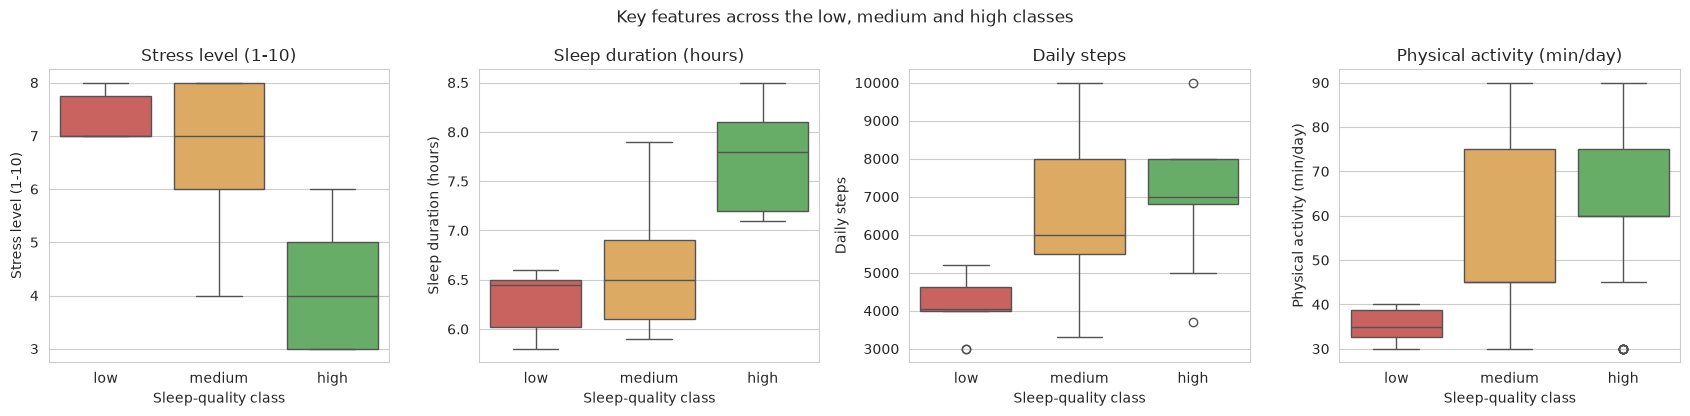

,age,daily_steps,heart_rate,physical_activity_level,sleep_duration,stress_level
sleep_quality_class,,,,,,
low,30.0,4050.0,80.0,35.0,6.4,7.0
medium,43.0,6000.0,72.0,45.0,6.5,7.0
high,41.0,7000.0,68.0,60.0,7.8,4.0


In [88]:
key_cols=["stress_level", "sleep_duration", "daily_steps", "physical_activity_level"]
fig, axes= plt.subplots(1,4, figsize=(17,4.2))
for i in range(4):
    sns.boxplot(x=CLASS, y=key_cols[i], data=df, ax=axes[i], order=class_order,
                hue=CLASS, hue_order=class_order, palette=class_colors, legend=False)
    axes[i].set_title(labels[key_cols[i]])
    axes[i].set_xlabel("Sleep-quality class")
    axes[i].set_ylabel(labels[key_cols[i]])
plt.suptitle("Key features across the low, medium and high classes")
plt.tight_layout()
plt.savefig(FIG + "/eda_08_features_by_class.png")
plt.show()
df.groupby(CLASS)[num_cols].median().loc[class_order].round(1)

Figure caption: The displayed box plots outputs stress level, sleep duration, physical activity and daily steps within each sleep-quality class. The median stress level falls from 6.8 (low) to 3.1 (high) and median sleep duration rises from 6.4 h to 7.5 h, while activity and steps illustrate a subtle, slight change.

Synthesis of figure findings

- 2091 records in total, with 8 input features, classes: low 21.6%, medium 51.6%, high 26.9%.
- Stress level feature is regarded as the strongest single factor that deteriorates sleep quality, as indicated by the Spearman's statistic (rho=-0.70), followed by increases heart rate (rho=-0.40), and sleep duration (rho=+0.32).
- Age, gender, BMI category, daily steps, and physical activity each have virtually no direct correlation with sleep quality - given that their |rho| yields a value less than 0.1.
- Daily steps and physical activity are highly correlated with an rho yielding a value of 0.83, implying that they carry redundant information.

## 3. Data Splitting and Model Preprocessing
3.1 Train/Test Split

3.2 Build Preprocessing Pipeline

### 3.1 Train/Test Split

In [89]:
train_df, test_df = train_test_split(
    df[FEATURES + [TARGET, CLASS]],
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df[CLASS]
)

X_train = train_df[FEATURES]
X_test = test_df[FEATURES]

y_reg_train = train_df[TARGET]
y_reg_test = test_df[TARGET]

y_clf_train = train_df[CLASS]
y_clf_test = test_df[CLASS]

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (105, 8)
Testing set: (27, 8)


### 3.2 Build Preprocessing Pipeline

In [90]:
def build_preprocessor():

    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            drop="if_binary",
            sparse_output=False
        ))
    ])

    return ColumnTransformer([
        ("num", numeric, NUM_FEATURES),
        ("cat", categorical, CAT_FEATURES)
    ])


def pipe(model):
    return Pipeline([
        ("prep", build_preprocessor()),
        ("model", model)
    ])

In [91]:
# export and save train/test split
df.to_csv(f"{OUT}/dataset1_clean.csv", index=False)
train_df.to_csv(f"{OUT}/train.csv", index=False)
test_df.to_csv(f"{OUT}/test.csv", index=False)

## 4. Feature Analysis and Engineering

We examine the relationships between input features and sleep quality, identify important predictors, and explore additional features that may improve model performance.

4.1 Feature Corralation Analysis
- Corralation Heatmap for Processed Features
- Corralation Analysis

4.2 Feature Engineering
- Engineered Features
- Engineered Features Pipline

4.3 Comparing Original VS Engineered Features
- Regression Evaluation and Findings
- Classification Evaluation and Findings 

### 4.1 Feature Corralation Analysis

In [ ]:
# we will work on copies to perserve original features for comparison
X_train_original = X_train.copy()
X_test_original = X_test.copy()

print("Training shape:", X_train_original.shape)
print("Testing shape:", X_test_original.shape)

#### Corralation Heatmap for Processed Features

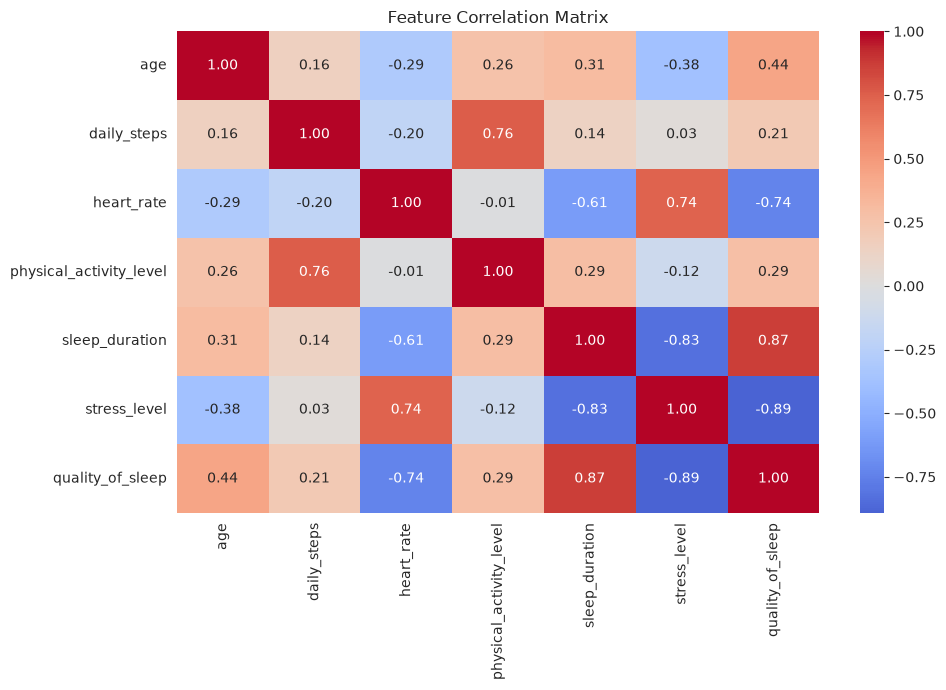

In [ ]:
# Combine numerical training features with the regression target
corr_data = X_train_original.select_dtypes(include="number").copy()
corr_data[TARGET] = y_reg_train

# Calculate Spearman correlations
corr_matrix = corr_data.corr(method="spearman")

# Display correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig(f"{FIG}/feature_analysis_correlation_heatmap.png", dpi=150)
plt.show()

#### Corralation Analysis/Findings
The heatmap shows that the two strongest relationships to sleep quality were stress level and sleep duration, with a respective corralation of -0.89 and 0.87, followed by heart rate at -0.74. This tells us that these features may be especially important for predicting sleep quality.

### 4.2 Feature Engineering
This section focuses on deriving new variables from our existing input features to see if it helps our models improve sleep quality prediction.

We will create the following four additional engineered features:

- **Stress-Sleep Interaction**: multiplies stress level by sleep duration
- **Stress-Heart Rate Interaction**: multiplies stress level by heart rate
- **Steps-per-Activity Level**: divides daily steps by physical activity level + 1
- **Sleep Deviation**: measures the absolute difference between sleep duration and the ideal 8 hours

Then, we will compare the models trained using the original 8 features VS models created using all 12 features

#### Engineered Features

In [ ]:

def create_features(X):
    X = X.copy()

    # Interaction between stress level and sleep duration
    X["stress_sleep_interaction"] = X["stress_level"] * X["sleep_duration"]

    # Interaction between stress level and heart rate
    X["stress_heart_interaction"] = X["stress_level"] * X["heart_rate"]

    # Daily steps relative to physical activity level
    X["steps_per_activity"] = X["daily_steps"] / (X["physical_activity_level"] + 1)

    # Deviation from 8 hours of sleep
    X["sleep_deviation"] = abs(X["sleep_duration"] - 8)

    return X


# Apply feature engineering to training and testing data
X_train_engineered = create_features(X_train_original)
X_test_engineered = create_features(X_test_original)

# Display engineered features
new_features = [
    "stress_sleep_interaction",
    "stress_heart_interaction",
    "steps_per_activity",
    "sleep_deviation"
]

print('New shapes:',X_train_engineered.shape, X_test_engineered.shape)
display(X_train_engineered[new_features].head())

New shapes: (105, 12) (27, 12)


,stress_sleep_interaction,stress_heart_interaction,steps_per_activity,sleep_deviation
46,28.8,272,114.754098,0.8
76,44.8,504,130.434783,1.6
66,43.8,432,87.323944,0.7
58,36.0,340,131.147541,0.8
29,48.0,576,161.290323,2.0


#### Engineered Features Pipeline 

In [95]:
# Create a pipeline that includes engineered features
def engineered_pipe(model):
    preprocessor = build_preprocessor()

    # Add engineered features to the numerical preprocessing
    preprocessor.transformers[0] = (
        "num",
        preprocessor.transformers[0][1],
        NUM_FEATURES + new_features
    )

    return Pipeline([
        ("prep", preprocessor),
        ("model", model)
    ])

## 4.3 Comparing Original VS Engineered Features

#### Regression Evaluation and Findings

In [96]:

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Compare original and engineered features
results = []

for name, model, X in [
    ("Original", pipe(LinearRegression()), X_train_original),
    ("Engineered", engineered_pipe(LinearRegression()), X_train_engineered)
]:
    scores = cross_validate(
        model,
        X,
        y_reg_train,
        cv=cv,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error"
        }
    )

    results.append({
        "Features": name,
        "CV R²": scores["test_r2"].mean(),
        "CV MAE": -scores["test_mae"].mean()
    })

# Create a comparison table
linear_comparison = pd.DataFrame(results)
original = linear_comparison.iloc[0]
engineered = linear_comparison.iloc[1]

comparison_table = pd.DataFrame({
    "Metric": ["CV R²", "CV MAE"],
    "Original": [original["CV R²"], original["CV MAE"]],
    "Engineered": [engineered["CV R²"], engineered["CV MAE"]],
    "Change": [
        engineered["CV R²"] - original["CV R²"],
        engineered["CV MAE"] - original["CV MAE"]
    ]
})

# display and save results
display(comparison_table.round(4).set_index("Metric"))

comparison_table.to_csv(f"{RES}/feature_engineering_linear_comparison.csv")

,Original,Engineered,Change
Metric,,,
CV R²,0.8804,0.8960,0.0156
CV MAE,0.3111,0.2665,-0.0447


**Linear Regression Feature Engineering Findings**

Both changes indicate improvement for Linear Regression with the engineered features. 

The mean CV R² slightly increased from 0.8804 to 0.8960, while MAE significantly decreased from 0.3111 to 0.2665 (14.35% reduction). 

#### Classification Evaluation and Findings

In [97]:

cv_clf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Compare original and engineered features
results_clf = []

for name, model, X in [
    ("Original", pipe(LogisticRegression(max_iter=1000)), X_train_original),
    ("Engineered", engineered_pipe(LogisticRegression(max_iter=1000)), X_train_engineered)
]:
    scores = cross_validate(
        model,
        X,
        y_clf_train,
        cv=cv_clf,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1_macro"
        }
    )

    results_clf.append({
        "Features": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Macro F1": scores["test_f1"].mean()
    })

# Create a comparison table
logistic_comparison = pd.DataFrame(results_clf)

original = logistic_comparison.iloc[0]
engineered = logistic_comparison.iloc[1]

logistic_table = pd.DataFrame({
    "Metric": ["CV Accuracy", "CV Macro F1"],
    "Original": [original["CV Accuracy"], original["CV Macro F1"]],
    "Engineered": [engineered["CV Accuracy"], engineered["CV Macro F1"]],
    "Change": [
        engineered["CV Accuracy"] - original["CV Accuracy"],
        engineered["CV Macro F1"] - original["CV Macro F1"]
    ]
})

# Display and save results
logistic_table = logistic_table.round(4).set_index("Metric")

display(logistic_table)

logistic_table.to_csv(f"{RES}/feature_engineering_logistic_comparison.csv")

,Original,Engineered,Change
Metric,,,
CV Accuracy,0.9143,0.9143,0.0
CV Macro F1,0.8639,0.8639,0.0


**Linear Regression Feature Engineering Findings**

There was no change to CV accuracy or macro F1-score, which means Logistic regression showed no improvement in classification with the added features, unlike Linear Regression.

## 5. Regression and Classification Models
5.1 Regression
- Train and Tune Models
- Test Set Evaluation

5.2 Classification
- Train and Tune Models
- Test Set Evaluation

### 5.1 Regression   

#### Train and Tune Models

In [98]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

# Define regression models using engineered features
reg_models = {
    "Mean Predictor": engineered_pipe(DummyRegressor(strategy="mean")),
    "Linear Regression": engineered_pipe(LinearRegression())
}

reg_rows = []

for name, model in reg_models.items():
    scores = cross_validate(
        model,
        X_train_engineered,
        y_reg_train,
        cv=kf,
        scoring=scoring
    )

    reg_rows.append({
        "model": name,
        "cv_r2": scores["test_r2"].mean(),
        "cv_mae": -scores["test_mae"].mean(),
        "cv_rmse": -scores["test_rmse"].mean()
    })

# Tune Ridge Regression
ridge_grid = GridSearchCV(
    engineered_pipe(Ridge()),
    {"model__alpha": [0.01, 0.1, 1, 10, 30, 100]},
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="r2"
)

ridge_grid.fit(X_train_engineered, y_reg_train)
best_ridge = ridge_grid.best_estimator_

print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"])

scores = cross_validate(
    ridge_grid,
    X_train_engineered,
    y_reg_train,
    cv=kf,
    scoring=scoring
)

reg_rows.append({
    "model": "Ridge Regression",
    "cv_r2": scores["test_r2"].mean(),
    "cv_mae": -scores["test_mae"].mean(),
    "cv_rmse": -scores["test_rmse"].mean()
})


reg_cv = pd.DataFrame(reg_rows)

display(reg_cv.round(4).set_index("model"))

reg_cv.to_csv(f"{RES}/regression_cv_results.csv", index=False)

Best Ridge alpha: 0.01


,cv_r2,cv_mae,cv_rmse
model,,,
Mean Predictor,-0.0425,1.0612,1.2508
Linear Regression,0.8960,0.2665,0.3724
Ridge Regression,0.8855,0.2876,0.3893


#### Test Set Evaluation

In [99]:
# Final evaluation of regression models on the held-out test set
# Fit each model on the full training set before making predictions

final_reg_models = {
    "Mean Predictor": engineered_pipe(DummyRegressor(strategy="mean")),
    "Linear Regression": engineered_pipe(LinearRegression()),
    "Ridge Regression": best_ridge
}

reg_test_rows = []

for name, model in final_reg_models.items():
    model.fit(X_train_engineered, y_reg_train)
    y_pred_reg = model.predict(X_test_engineered)

    reg_test_rows.append({
        "model": name,
        "train_r2": model.score(X_train_engineered, y_reg_train),
        "test_r2": r2_score(y_reg_test, y_pred_reg),
        "test_mae": mean_absolute_error(y_reg_test, y_pred_reg),
        "test_rmse": mean_squared_error(y_reg_test, y_pred_reg) ** 0.5
    })

reg_test = pd.DataFrame(reg_test_rows)

# Combine cross-validation and test results into one table
reg_final = reg_cv.merge(reg_test, on="model")

display(reg_final.round(4).set_index("model"))

reg_final.to_csv(f"{RES}/regression_final_results.csv", index=False)

,cv_r2,cv_mae,cv_rmse,train_r2,test_r2,test_mae,test_rmse
model,,,,,,,
Mean Predictor,-0.0425,1.0612,1.2508,0.0000,-0.0105,1.0878,1.3289
Linear Regression,0.8960,0.2665,0.3724,0.9352,0.9510,0.2190,0.2927
Ridge Regression,0.8855,0.2876,0.3893,0.9349,0.9489,0.2228,0.2988


### 5.2 Classification

#### Train and Tune Model

In [100]:
skf = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

clf_models = {
    "Majority Class": pipe(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": pipe(LogisticRegression(max_iter=2000))
}

clf_scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro"
}

clf_rows = []

for name, model in clf_models.items():
    scores = cross_validate(
        model, X_train, y_clf_train,
        cv=skf, scoring=clf_scoring
    )

    clf_rows.append({
        "model": name,
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_f1_macro": scores["test_f1_macro"].mean()
    })

# Tune Logistic Regression
logit_grid = GridSearchCV(
    pipe(LogisticRegression(max_iter=2000)),
    {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },
    cv=skf,
    scoring="f1_macro"
)

logit_grid.fit(X_train, y_clf_train)
best_logit = logit_grid.best_estimator_

print("Best Logistic Regression parameters:", logit_grid.best_params_)

scores = cross_validate(
    best_logit, X_train, y_clf_train,
    cv=skf, scoring=clf_scoring
)

clf_rows.append({
    "model": "Tuned Logistic Regression",
    "cv_accuracy": scores["test_accuracy"].mean(),
    "cv_f1_macro": scores["test_f1_macro"].mean()
})

clf_cv = pd.DataFrame(clf_rows)

display(clf_cv.round(4).set_index("model"))

clf_cv.to_csv(f"{RES}/classification_cv_results.csv", index=False)

Best Logistic Regression parameters: {'model__C': 10, 'model__class_weight': None}


,cv_accuracy,cv_f1_macro
model,,
Majority Class,0.4952,0.2207
Logistic Regression,0.9143,0.8639
Tuned Logistic Regression,0.9333,0.9231


#### Test Set Evaluation

In [101]:
# Final evaluation of classification models on the held-out test set
# Fit each model on the full training set before making predictions

final_clf_models = {
    "Majority Class": pipe(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": pipe(LogisticRegression(max_iter=2000)),
    "Tuned Logistic Regression": best_logit
}

clf_test_rows = []

for name, model in final_clf_models.items():
    model.fit(X_train, y_clf_train)
    y_pred_clf = model.predict(X_test)

    clf_test_rows.append({
        "model": name,
        "train_accuracy": accuracy_score(y_clf_train, model.predict(X_train)),
        "test_accuracy": accuracy_score(y_clf_test, y_pred_clf),
        "test_f1_macro": f1_score(y_clf_test, y_pred_clf, average="macro")
    })

clf_test = pd.DataFrame(clf_test_rows)

# Combine cross-validation and test results into one table
clf_final = clf_cv.merge(clf_test, on="model")

display(clf_final.round(4).set_index("model"))

clf_final.to_csv(f"{RES}/classification_final_results.csv", index=False)

,cv_accuracy,cv_f1_macro,train_accuracy,test_accuracy,test_f1_macro
model,,,,,
Majority Class,0.4952,0.2207,0.4952,0.4815,0.2167
Logistic Regression,0.9143,0.8639,0.9619,0.8889,0.6163
Tuned Logistic Regression,0.9333,0.9231,0.9810,0.9259,0.8499


## 6. Random Forest Regression and Classification Models
6.1 Random Forest Regressor
- Train Model
- Tune Using GridSearchCV
- Overfitting Analysis
- Original VS Engineered Features Evaluation 
- Test Set Evaluation
- Predicted VS Actual Graph
- Feature Importance Analysis

6.2 Random Forest Classifier
- Train Model
- Tune Using GridSearchCV
- Overfitting Analysis
- Test Set Evaluation and Confusion Matrix
- Feature Importance Analysis

### 6.1 Random Forest Regressor

#### Training and Tuning the Model

Train a forest using default settings parameters to determine baseline performance and further tune parameters to optimize model performance

In [102]:
# create Random Forest Regressor with the existing preprocessing pipeline
rf = pipe(RandomForestRegressor(random_state=RANDOM_STATE))

# evaluate using 5-fold cross-validation
rf_scores = cross_validate(
    rf,
    X_train,
    y_reg_train,
    cv=kf,
    scoring="r2",
    return_train_score=True
)

# calculate average training and validation R²
rf_train_r2 = rf_scores["train_score"].mean()
rf_cv_r2 = rf_scores["test_score"].mean()

# display results
print("Training R²:", round(rf_train_r2, 3))
print("CV R²:", round(rf_cv_r2, 3))
print("Overfitting gap:", round(rf_train_r2 - rf_cv_r2, 3))

Training R²: 0.987
CV R²: 0.915
Overfitting gap: 0.073


Original layan markdown: Results indicate an overfitting trend, where the regressor was capable of accurately predicting its training data. However, its performance drastically shrinked when feeding it with unseen data, demonstrating how it lacks strong generalization property. This suggests that the model merely memorized given training sets rather than capturing underlying patterns, and so it requires further parameter tuning using the GridSearchCV technique that limits the depth of the trees grown.

suggested analysis: The default Random Forest Regressor was evaluated using five-fold cross-validation. It achieved an average training R² of 0.987 and a cross-validation R² of 0.915, resulting in a gap of 0.073. This suggests some overfitting, although the model maintains strong validation performance.

The Random Forest also achieved a higher cross-validation R² than the previously evaluated Linear Regression model (0.896), indicating promising predictive performance before hyperparameter tuning.

Tuning RF regressor using GridSearchCV

In [103]:
# Define the grid search parameters
param_grid = {
    "model__n_estimators": [100,300], # Number of trees in the forest - 100 is often the ideal starting point balancing between model performance and computational efficiency while 300 trees provides robust model performance at the cost of more computational time
    "model__max_depth":[4,6,8,10,None], # controls the depth of the tree - prevents overfitting and allow generalization to unseen data by limiting complexity and capture essential patterns
    "model__min_samples_leaf":[1,5,10]
}

# tune RF using 5-fold cross-validation
rf_grid = GridSearchCV(estimator=rf, param_grid=param_grid, cv=kf, scoring="r2", return_train_score=True, n_jobs=-1) # n_jobs=-1 utilizes all available CPU cores to speed up exhaustive search process

# fit grid search on training data
rf_grid.fit(X_train, y_reg_train)

# display best hyperparameters
print("Best parameter settings: ", rf_grid.best_params_)
print("Best CV R2: ", round(rf_grid.best_score_, 3))


Best parameter settings:  {'model__max_depth': 6, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Best CV R2:  0.917


#### Overfitting Analysis

Model overfitting check and its plot to gain a visual intuition

In [104]:
#  cross-validation results from GridSearchCV
rf_results = pd.DataFrame(rf_grid.cv_results_)
rf_results = rf_results[
    ["param_model__n_estimators",
        "param_model__max_depth",
        "param_model__min_samples_leaf",
        "mean_train_score",
        "mean_test_score"]] # select relevant columns for analysis and comparison of model performance across different combinations

# Rename columns for readability
rf_results = rf_results.rename(columns={
    "param_model__n_estimators": "n_estimators",
    "param_model__max_depth": "max_depth",
    "param_model__min_samples_leaf": "min_samples_leaf",
    "mean_train_score": "Train R²",
    "mean_test_score": "CV R²"
})

# Derive a new column, gap, to quantify differences in training and testing performance which help observe potential overfitting/underfitting issues and guide further model tunes
rf_results["Overfitting gap"]= rf_results["Train R²"] - rf_results["CV R²"] 

rf_results = rf_results.sort_values(by="CV R²", ascending=False) #sort by performance
display(rf_results.round(3).head(10)) 

,n_estimators,max_depth,min_samples_leaf,Train R²,CV R²,Overfitting gap
7,300,6,1,0.987,0.917,0.070
13,300,8,1,0.988,0.917,0.070
25,300,None,1,0.988,0.917,0.070
19,300,10,1,0.988,0.917,0.070
1,300,4,1,0.982,0.916,0.066
6,100,6,1,0.987,0.915,0.072
18,100,10,1,0.987,0.915,0.073
24,100,None,1,0.987,0.915,0.073
12,100,8,1,0.987,0.915,0.073
0,100,4,1,0.981,0.913,0.068


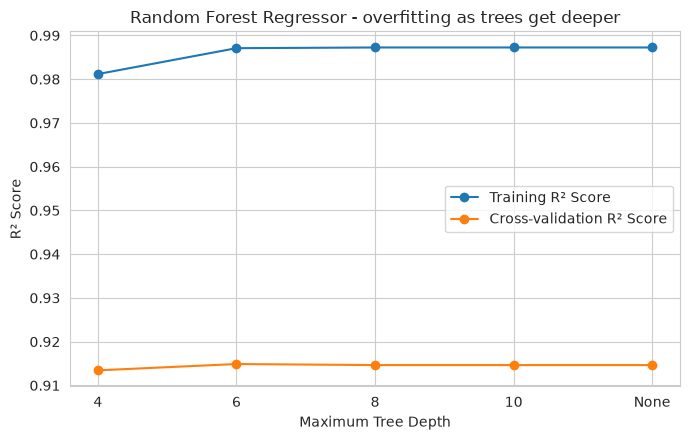

In [105]:
# Visual intuition of how overfitting increases as tree depth grows

deep = rf_results[(rf_results["n_estimators"] == 100) & (rf_results["min_samples_leaf"] == 1)].copy()
deep = deep.sort_values("max_depth")  # put rows in depth order (4, 6, 8, 10, None) to match the labels
tree_depth_labels= ["4","6","8","10","None"]

# Create labels for tree depth
tree_depth_labels = ["4", "6", "8", "10", "None"]

# Plot training and cross-validation R²
plt.figure(figsize=(7, 4.5))
plt.plot(tree_depth_labels, deep["Train R²"], marker="o", label="Training R² Score")
plt.plot(tree_depth_labels, deep["CV R²"], marker="o", label="Cross-validation R² Score")
plt.title("Random Forest Regressor - overfitting as trees get deeper")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("R² Score")
plt.legend()
plt.tight_layout()

# Save figure
plt.savefig(f"{FIG}/rf_01_regressor_overfitting.png", dpi=150, bbox_inches="tight")
plt.show()

Original Markdown: The line plot illustrates how overfitting increases as tree depth grows. The training R2 score increases with deeper trees, while cross validation score decreases, indicating model fits the data overly well and fails to generalize. This represents a classic case of overfitting, where the model captures noise and specific patterns in the training data that dont generalize to unseen data, increasing the need for further parameter tuning.

suggested markdown: The graph shows that both training and cross-validation R² improve slightly as maximum tree depth increases from 4 to 6, before stabilizing at greater depths. The consistent gap between the two scores indicates some overfitting, although validation performance remains strong. These findings support the selected maximum depth of 6, as deeper trees provide little additional improvement.

#### Original VS Engineered Features for Random Forest Regression
To investigate whether feature engineering improves Random Forest performance, the tuned model is evaluated using both the original and engineered feature sets. Both versions use identical hyperparameters and five-fold cross-validation to ensure a consistent comparison.

In [106]:
# Compare the tuned Random Forest Regressor using original and engineered features
# Both models use the same hyperparameters and cross-validation folds.

rf_params = rf_grid.best_params_

rf_original = pipe(RandomForestRegressor(
    n_estimators=rf_params["model__n_estimators"],
    max_depth=rf_params["model__max_depth"],
    min_samples_leaf=rf_params["model__min_samples_leaf"],
    random_state=RANDOM_STATE
))

rf_engineered = engineered_pipe(RandomForestRegressor(
    n_estimators=rf_params["model__n_estimators"],
    max_depth=rf_params["model__max_depth"],
    min_samples_leaf=rf_params["model__min_samples_leaf"],
    random_state=RANDOM_STATE
))

# Evaluate both feature sets using the same five-fold cross-validation
rf_original_scores = cross_validate(
    rf_original, X_train_original, y_reg_train,
    cv=kf, scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"]
)

rf_engineered_scores = cross_validate(
    rf_engineered, X_train_engineered, y_reg_train,
    cv=kf, scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"]
)

# Compare average cross-validation performance
rf_feature_comparison = pd.DataFrame({
    "Feature Set": ["Original", "Engineered"],
    "CV R²": [
        rf_original_scores["test_r2"].mean(),
        rf_engineered_scores["test_r2"].mean()
    ],
    "CV MAE": [
        -rf_original_scores["test_neg_mean_absolute_error"].mean(),
        -rf_engineered_scores["test_neg_mean_absolute_error"].mean()
    ],
    "CV RMSE": [
        -rf_original_scores["test_neg_root_mean_squared_error"].mean(),
        -rf_engineered_scores["test_neg_root_mean_squared_error"].mean()
    ]
})

display(rf_feature_comparison.round(4))

rf_feature_comparison.to_csv(
    f"{RES}/rf_regressor_feature_comparison.csv",
    index=False
)

,Feature Set,CV R²,CV MAE,CV RMSE
0,Original,0.9175,0.1652,0.3224
1,Engineered,0.9310,0.1372,0.2837


The engineered feature set was selected for the final Random Forest Regressor because it achieved better cross-validation performance across all three metrics. Compared with the original features, the engineered version increased CV R² from 0.9175 to 0.9310, while reducing CV MAE from 0.1652 to 0.1372 and CV RMSE from 0.3224 to 0.2837.

Based on these results, the engineered Random Forest Regressor will be fitted on the full training set and evaluated on the held-out test set.

#### Final Evaluation On Test Set

Test set evaluation using R^2, MAE, RMSE statistical metrics

In [107]:
# Testing optimal parameters on new test set to evaluate model performance
best_rf = rf_engineered.fit(X_train_engineered, y_reg_train)
y_pred = best_rf.predict(X_test_engineered)

# Evaluate the tuned Random Forest Regressor using three metrics
# Each one grades the predictions differently, so together they give a fuller picture.

# Train R2: how well the model fits the people it learned from (the "practice" score).
# Compare it with Test R2 below: a large gap would mean overfitting (memorising).
print("Train R2:", round(best_rf.score(X_train_engineered, y_reg_train), 3))

# Test R2: how much better the model is than guessing the average score for everyone,
# measured on unseen people. 0 = no better than guessing, 1 = perfect predictions.
print("Test R2:", round(r2_score(y_reg_test, y_pred), 3))

# Test MAE (Mean Absolute Error): on average, how many points (out of 10)
# the predictions are away from the real sleep-quality scores.
print("Test MAE:", round(mean_absolute_error(y_reg_test, y_pred), 3))

# Test RMSE (Root Mean Squared Error): like MAE, but squares each error first,
# so big misses count more. "** 0.5" takes the square root to return to score points.
# If RMSE is much larger than MAE, the model makes some large mistakes.
print("Test RMSE:", round(mean_squared_error(y_reg_test, y_pred) ** 0.5, 3))

Train R2: 0.992
Test R2: 0.882
Test MAE: 0.207
Test RMSE: 0.455


#### Random Forest Regressor — Test Set Evaluation

The tuned Random Forest Regressor, using the engineered feature set, achieved a test R² of 0.882, indicating that it explains approximately 88.2% of the variation in sleep-quality scores. The model obtained a test MAE of 0.207 and RMSE of 0.455, demonstrating relatively small prediction errors overall.

Although the test R² was lower than the training R² of 0.992, the model maintained strong performance on unseen data. The difference suggests some overfitting, while the larger RMSE relative to MAE indicates that certain predictions may have higher errors.

Constructing predicted vs. actual plots pertaining to sleep quality after parameter tuning

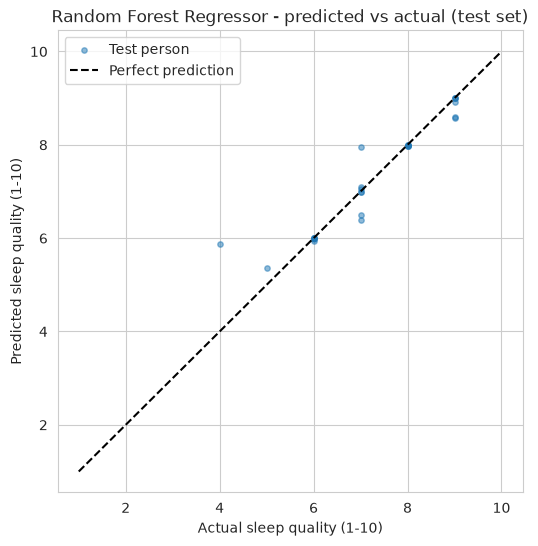

In [108]:
# Compare each test person's real sleep score with the model's prediction.
# Points on the dashed line are perfect predictions; distance from the line = error.
plt.figure(figsize=(6, 6))
plt.scatter(y_reg_test, y_pred, s=15, alpha=0.5, label="Test person")
plt.plot([1, 10],[1, 10], "k--", label="Perfect prediction") # k-- = keyword for black dashed line
plt.title("Random Forest Regressor - predicted vs actual (test set)")
plt.xlabel("Actual sleep quality (1-10)")
plt.ylabel("Predicted sleep quality (1-10)")
plt.legend()
plt.savefig(f"{FIG}/rf_02_regressor_pred_vs_actual.png")
plt.show()

Suggested markdown: The predicted-versus-actual plot shows that most predictions are close to the perfect-prediction line, indicating that the Random Forest Regressor generally estimates sleep-quality scores accurately. However, a noticeable overestimation occurs for a participant with an actual sleep-quality score of approximately 4, which may contribute to the higher RMSE relative to MAE. Overall, the visualization supports the model's strong test performance while highlighting occasional larger prediction errors.

#### Random Forest Regressor Feature Importance

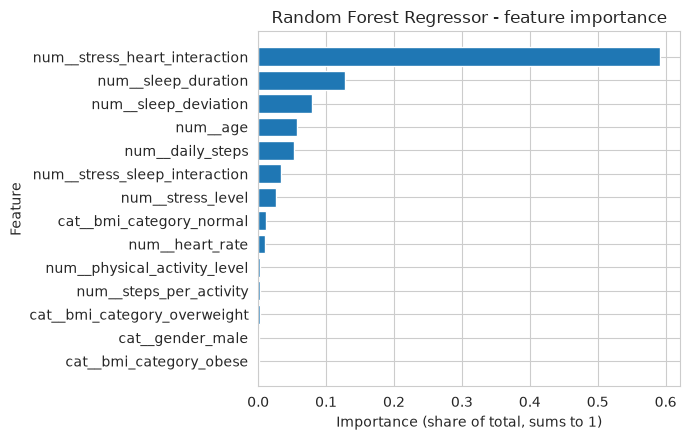

In [109]:
# Feature importance: how much each feature helped the forest make its predictions.
# The values add up to 1, so each one is that feature's share of the total.
importance = pd.Series(
    best_rf.named_steps["model"].feature_importances_,
    index=best_rf.named_steps["prep"].get_feature_names_out()
)
importance = importance.sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(importance.index, importance.values) # barh() creates a horizontal bar plot where the y-axis represents feature names and the x-axis represents its corresponding values- stacks data through bottom up approach - enhances interpretability of feature importance as it helps easily identify the dominating feature that strongly impacts the target
plt.title("Random Forest Regressor - feature importance")
plt.xlabel("Importance (share of total, sums to 1)")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(f"{FIG}/rf_03_regressor_feature_importance.png")
plt.show()

#### Feature Importance Analysis

The feature importance analysis shows that the engineered stress_heart_interaction feature is the most influential predictor, accounting for approximately 59% of the model's total importance. Sleep duration follows at around 13%, while the engineered sleep_deviation feature contributes approximately 8%. Age and daily steps also show moderate importance, whereas the remaining features contribute relatively little.

Compared with the original feature set, the engineered model distributes importance differently, highlighting the potential value of combining existing predictors. However, these importance scores describe how the Random Forest uses features for prediction and do not establish causal relationships.

In [110]:
# Collect the regressor's key scores into a one-row table and save it,
# so the team can compare it with Hams's baseline models in the report.
rf_reg_results = pd.DataFrame([{
    "model": "Random Forest Regressor (tuned, engineered)",
    "cv_r2": rf_feature_comparison.loc[rf_feature_comparison["Feature Set"] == "Engineered", "CV R²"].iloc[0], # average R2 across the 5 CV folds
    "cv_r2_std": rf_engineered_scores["test_r2"].std(), # how much the 5 fold scores varied
    "train_r2": best_rf.score(X_train_engineered, y_reg_train),
    "test_r2": r2_score(y_reg_test, y_pred),
    "test_mae": mean_absolute_error(y_reg_test, y_pred),
    "test_rmse": mean_squared_error(y_reg_test, y_pred) ** 0.5
}]).round(3)

rf_reg_results.to_csv(f"{RES}/rf_regressor_results.csv", index=False)
rf_reg_results

,model,cv_r2,cv_r2_std,train_r2,test_r2,test_mae,test_rmse
0,"Random Forest Regressor (tuned, engineered)",0.931,0.057,0.992,0.882,0.207,0.455


### Synthesizing Random Forest Regressor Results (fix this)

- **Tuning:** GridSearchCV (5-fold CV, 30 combinations) selected `max_depth=6`, `min_samples_leaf=10`, `n_estimators=100` (CV R² = 0.469).
- **Overfitting:** the default forest scored R² 0.923 on training data but only 0.504 on the test set. Limiting tree depth and leaf size reduced the train–test gap from 0.42 to 0.05.
- **Test performance:** R² = 0.533, MAE = 0.725, RMSE = 0.922. Predictions are off by about 0.7 points on the 1–10 scale on average.
- **Comparison:** performance is close to Linear Regression (test R² 0.545), suggesting the relationship between lifestyle factors and sleep quality is largely linear in this dataset.
- **Feature importance:** stress level dominates (≈0.83 of total importance); sleep duration, activity, age, steps and heart rate contribute little extra, and BMI and gender minimally contribute.
- **Limitation:** the model pulls extreme scores toward the average, overestimating low sleep quality and underestimating high sleep quality.

### 6.2 Random Forest Classifier

#### Training and Tuning the Model

Developing the default forest model (unlimited tree depth) to observe potential overfitting patterns

In [111]:
rf_clf = pipe(RandomForestClassifier(random_state=RANDOM_STATE))

rf_clf_scores = cross_validate(
    rf_clf,
    X_train,
    y_clf_train,
    cv=skf,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
    return_train_score=True
)

train_accuracy = rf_clf_scores["train_accuracy"].mean()
cv_accuracy = rf_clf_scores["test_accuracy"].mean()
cv_f1 = rf_clf_scores["test_f1_macro"].mean()

print("Train accuracy:", round(train_accuracy, 3))
print("CV accuracy:", round(cv_accuracy, 3))
print("CV macro F1:", round(cv_f1, 3))

Train accuracy: 1.0
CV accuracy: 0.952
CV macro F1: 0.91


In [112]:
param_grid_classif = {
    "model__n_estimators": [300],
    "model__max_depth": [4, 6, 8, 10, None],
    "model__min_samples_leaf": [1, 5, 10],
    "model__class_weight": [None, "balanced"]
}

grid_classif = GridSearchCV(
    rf_clf,
    param_grid_classif,
    cv=skf,
    scoring="f1_macro",
    return_train_score=True,
    n_jobs=-1
)

grid_classif.fit(X_train, y_clf_train)

print("Best settings:", grid_classif.best_params_)
print("Best CV macro F1:", round(grid_classif.best_score_, 3))

Best settings: {'model__class_weight': 'balanced', 'model__max_depth': 4, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Best CV macro F1: 0.928


#### Overfitting Analysis

rows found: 5


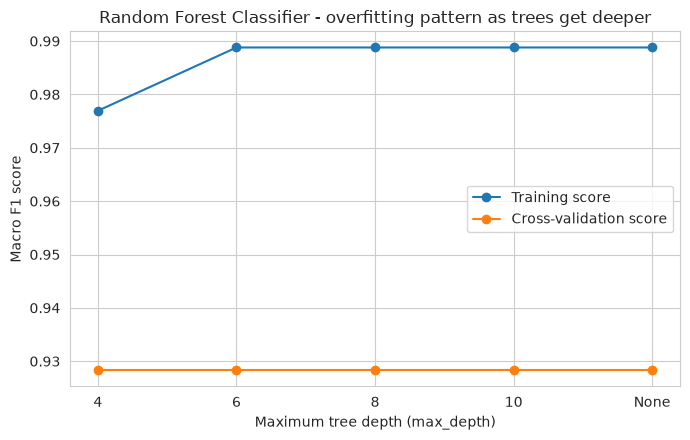

,param_model__max_depth,mean_train_score,mean_test_score,gap
15,4,0.977,0.928,0.049
18,6,0.989,0.928,0.061
21,8,0.989,0.928,0.061
24,10,0.989,0.928,0.061
27,None,0.989,0.928,0.061


In [113]:
results_classif = pd.DataFrame(grid_classif.cv_results_)
results_classif["gap"] = results_classif["mean_train_score"] - results_classif["mean_test_score"]

deep_classif = results_classif[
    (results_classif["param_model__class_weight"] == "balanced") &
    (results_classif["param_model__n_estimators"] == 300) &
    (results_classif["param_model__min_samples_leaf"] == 1)
].copy()

# Ensure tree depths appear in the correct order
depth_order = [4, 6, 8, 10, None]
deep_classif["depth_order"] = deep_classif["param_model__max_depth"].apply(
    lambda x: depth_order.index(x)
)
deep_classif = deep_classif.sort_values("depth_order")

print("rows found:", len(deep_classif))

depth_labels = ["4", "6", "8", "10", "None"]
plt.figure(figsize=(7, 4.5))
plt.plot(depth_labels, deep_classif["mean_train_score"], "o-", label="Training score")
plt.plot(depth_labels, deep_classif["mean_test_score"], "o-", label="Cross-validation score")
plt.title("Random Forest Classifier - overfitting pattern as trees get deeper")
plt.xlabel("Maximum tree depth (max_depth)")
plt.ylabel("Macro F1 score")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/rf_04_classifier_overfitting.png")
plt.show()

deep_classif[["param_model__max_depth", "mean_train_score", "mean_test_score", "gap"]].round(3)

The overfitting analysis shows that increasing the maximum tree depth beyond 4 does not improve cross-validation performance. All tested depths achieved a CV macro F1 of approximately 0.928, while the training macro F1 increased from 0.977 at depth 4 to 0.989 at greater depths. Consequently, the training–validation gap increased from 0.049 to 0.061.

These results support selecting a maximum depth of 4, as it achieves comparable validation performance with lower model complexity and a smaller overfitting gap.

#### Test set evaluation and Confusion Matrix

Test accuracy: 0.963
Test macro F1: 0.877
              precision    recall  f1-score   support

         low      1.000     0.500     0.667         2
      medium      0.929     1.000     0.963        13
        high      1.000     1.000     1.000        12

    accuracy                          0.963        27
   macro avg      0.976     0.833     0.877        27
weighted avg      0.966     0.963     0.957        27



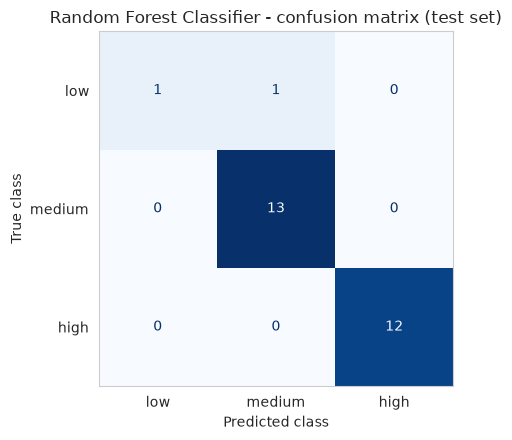

In [114]:
best_classif = grid_classif.best_estimator_     # provides chosen settings, retrained on all training data
y_clf_pred = best_classif.predict(X_test)       # predicted class (low/medium/high) for each testing data

print("Test accuracy:", round(accuracy_score(y_clf_test, y_clf_pred), 3))
print("Test macro F1:", round(f1_score(y_clf_test, y_clf_pred, average="macro"), 3)) # average = "macro" treats each class fairly by scoring each individually then averages them
# Precision, recall and F1 for each class separately; digits=3 shows 3 decimals
print(classification_report(y_clf_test, y_clf_pred, labels=CLASS_ORDER, digits=3))

# Confusion matrix: rows = true class, columns = predicted class.
# Diagonal cells are correct predictions; off-diagonal cells show which classes are misclassified
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_clf_test, y_clf_pred, labels=CLASS_ORDER,
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Random Forest Classifier - confusion matrix (test set)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.grid(False)    # removes grid for better readability
plt.tight_layout()
plt.savefig(f"{FIG}/rf_05_classifier_confusion_matrix.png")
plt.show()

The tuned Random Forest Classifier achieved a test accuracy of 96.3% and a macro F1 score of 0.877, correctly classifying 26 out of 27 test observations. The confusion matrix shows that all 13 medium-quality and 12 high-quality observations were classified correctly, while one of the two low-quality observations was incorrectly classified as medium.

Although the overall accuracy is high, the lower recall of 0.500 for the low-quality class highlights a limitation in identifying less-represented cases. This also explains why the macro F1 score is lower than accuracy. Given the small test set, particularly the limited number of low-quality observations, these results should be interpreted cautiously.

#### Random Forest Classifier Feature Importance

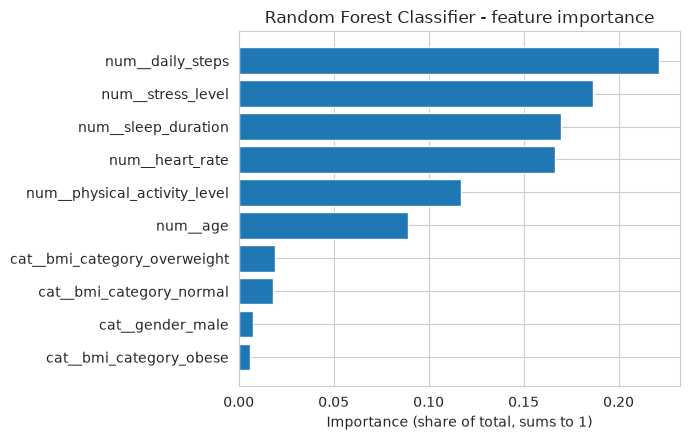

num__daily_steps                0.221
num__stress_level               0.186
num__sleep_duration             0.170
num__heart_rate                 0.167
num__physical_activity_level    0.117
num__age                        0.089
cat__bmi_category_overweight    0.019
cat__bmi_category_normal        0.018
cat__gender_male                0.007
cat__bmi_category_obese         0.006
dtype: float64

In [115]:
importance_classif = pd.Series(
    best_classif.named_steps["model"].feature_importances_,
    index=best_classif.named_steps["prep"].get_feature_names_out()
)
importance_classif = importance_classif.sort_values()          # ascending, so barh puts the biggest bar on top

plt.figure(figsize=(7, 4.5))
plt.barh(importance_classif.index, importance_classif.values)
plt.title("Random Forest Classifier - feature importance")
plt.xlabel("Importance (share of total, sums to 1)")
plt.tight_layout()
plt.savefig(f"{FIG}/rf_06_classifier_feature_importance.png")
plt.show()

importance_classif.sort_values(ascending=False).round(3)   # display it as a table

The Random Forest Classifier's feature importance analysis identifies daily steps as the most influential predictor, contributing 22.1% of the total importance. Stress level (18.6%), sleep duration (17.0%), and heart rate (16.7%) also play significant roles, followed by physical activity level (11.7%) and age (8.9%). In contrast, BMI category and gender contribute relatively little to the model's predictions.

Unlike the engineered Random Forest Regressor, which relies heavily on the stress–heart interaction feature, the classifier distributes importance more evenly across several lifestyle factors. These results highlight differences in how the two models use their input features, although feature importance does not establish causal relationships.

In [116]:
# Saving the RF classifier scores as a one-row table, saved next to the regressor's results for easy comparison
rf_clf_results = pd.DataFrame([{
    "model": "Random Forest Classifier (tuned)",
    "cv_f1_macro": grid_classif.best_score_,
    "test_accuracy": accuracy_score(y_clf_test, y_clf_pred),
    "test_f1_macro": f1_score(y_clf_test, y_clf_pred, average="macro")
}]).round(3)

rf_clf_results.to_csv(f"{RES}/rf_classifier_results.csv", index=False)

rf_clf_results

,model,cv_f1_macro,test_accuracy,test_f1_macro
0,Random Forest Classifier (tuned),0.928,0.963,0.877


## 7. Final Model Comparison and Selection
7.1 Regression Model Comparison

7.2 Classification Model Comparison

7.3 Final Model Selection
- Regression Model Selection
- Classification Model Selection

### 7.1 Regression Model Comparison

In [117]:
# Load the saved regression results from Sections 5 and 6
reg_baselines = pd.read_csv(f"{RES}/regression_final_results.csv")
rf_reg_results = pd.read_csv(f"{RES}/rf_regressor_results.csv")

# Combine the baseline regression models with the Random Forest Regressor
reg_comparison = pd.concat(
    [reg_baselines, rf_reg_results],
    ignore_index=True
)

# Select the metrics needed for comparison
reg_comparison = reg_comparison[
    ["model", "cv_r2", "train_r2", "test_r2", "test_mae", "test_rmse"]
]

# Display the comparison table
display(reg_comparison.round(4).set_index("model"))

# Save the final regression comparison
reg_comparison.to_csv(f"{RES}/regression_model_comparison.csv", index=False)

,cv_r2,train_r2,test_r2,test_mae,test_rmse
model,,,,,
Mean Predictor,-0.0425,0.0000,-0.0105,1.0878,1.3289
Linear Regression,0.8960,0.9352,0.9510,0.2190,0.2927
Ridge Regression,0.8855,0.9349,0.9489,0.2228,0.2988
"Random Forest Regressor (tuned, engineered)",0.9310,0.9920,0.8820,0.2070,0.4550


### 7.2 Classification Model Comparison

In [ ]:
# Load the saved classification results from Sections 5 and 6
clf_baselines = pd.read_csv(f"{RES}/classification_final_results.csv")
rf_clf_results = pd.read_csv(f"{RES}/rf_classifier_results.csv")

# Combine the baseline classification models with the Random Forest Classifier
clf_comparison = pd.concat(
    [clf_baselines, rf_clf_results],
    ignore_index=True
)

# Select the metrics needed for comparison
clf_comparison = clf_comparison[
    ["model", "cv_f1_macro", "test_accuracy", "test_f1_macro"]
]

# Display the comparison table
display(clf_comparison.round(4).set_index("model"))

# Save the final classification comparison
clf_comparison.to_csv(f"{RES}/classification_model_comparison.csv", index=False)

,cv_f1_macro,test_accuracy,test_f1_macro
model,,,
Majority Class,0.2207,0.4815,0.2167
Logistic Regression,0.8639,0.8889,0.6163
Tuned Logistic Regression,0.9231,0.9259,0.8499
Random Forest Classifier (tuned),0.9280,0.9630,0.8770


### 7.3 Final Model Selection

#### Regression Model Selection

Linear Regression was selected as the final regression model. Although the tuned Random Forest Regressor achieved a higher cross-validation R² (0.931 compared with 0.896), Linear Regression performed better on the held-out test set, achieving an R² of 0.951 and RMSE of 0.293. Random Forest achieved a slightly lower MAE (0.207 compared with 0.219), but its larger training–test performance gap suggests a greater risk of overfitting. Considering its strong performance and simpler structure, Linear Regression was selected for predicting numerical sleep-quality scores.

#### Classification Model Selection

The tuned Random Forest Classifier was selected as the final classification model. It achieved the highest cross-validation macro F1 (0.928), test accuracy (0.963), and test macro F1 (0.877), outperforming both standard and tuned Logistic Regression. These results suggest that Random Forest is a promising approach for classifying sleep quality into low, medium, and high categories.

#### Overall Conclusion

The results demonstrate that different algorithms can be more suitable for different prediction tasks. Linear Regression was selected for predicting continuous sleep-quality scores, while Random Forest Classification was selected for predicting sleep-quality categories. Both models benefited from preprocessing and systematic evaluation. However, because the dataset contains only 132 observations, further validation using a larger, independent dataset is recommended before applying the models in real-world settings.